# 03 — Régression linéaire : prévision de la consommation de base
Entrée : `data/processed/consumption_hourly.csv` (produit par le notebook 01).
Cible : `mean_kwh` = consommation moyenne par foyer et par heure.

Étapes : features → découpage temporel → baselines → régression linéaire → Ridge / Lasso → validation croisée temporelle → analyse des résidus → sauvegarde.
Le code du modèle est dans `src/models/linear_regression.py`.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.models.linear_regression import (build_features, split_chronological, baseline_metrics,
                                          compute_metrics, ConsumptionModel, time_series_cv)
sns.set_theme(style="whitegrid")
FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Chargement et features

In [2]:
df = pd.read_csv("../data/processed/consumption_hourly.csv", index_col=0, parse_dates=True)
X, y = build_features(df)
print(X.shape)
print("Features :", list(X.columns))
X.head()

(19018, 17)
Features : ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_weekend', 'is_holiday', 'temperature', 'humidity', 'windSpeed', 'lag_1', 'lag_2', 'lag_24', 'lag_48', 'lag_168', 'roll_mean_24']


,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,is_weekend,is_holiday,temperature,humidity,windSpeed,lag_1,lag_2,lag_24,lag_48,lag_168,roll_mean_24
timestamp,,,,,,,,,,,,,,,,,
2011-12-28 15:00:00,-0.707107,-7.071068e-01,0.974928,-0.222521,-2.449294e-16,1.0,0,0,8.96,0.64,7.04,0.500170,0.520062,0.564035,0.519292,0.535041,0.476937
2011-12-28 16:00:00,-0.866025,-5.000000e-01,0.974928,-0.222521,-2.449294e-16,1.0,0,0,7.88,0.65,6.71,0.499840,0.500170,0.583946,0.590789,0.574089,0.474262
2011-12-28 17:00:00,-0.965926,-2.588190e-01,0.974928,-0.222521,-2.449294e-16,1.0,0,0,7.39,0.66,6.58,0.563277,0.499840,0.659779,0.590156,0.692239,0.473401
2011-12-28 18:00:00,-1.000000,-1.836970e-16,0.974928,-0.222521,-2.449294e-16,1.0,0,0,6.88,0.69,6.84,0.692223,0.563277,0.654649,0.638967,0.759327,0.474753
2011-12-28 19:00:00,-0.965926,2.588190e-01,0.974928,-0.222521,-2.449294e-16,1.0,0,0,6.42,0.73,7.07,0.721944,0.692223,0.691353,0.609821,0.758298,0.477557


## 2. Découpage temporel (70 % train / 15 % validation / 15 % test)
Pas de mélange aléatoire : on ne doit jamais prédire le passé avec le futur.

In [3]:
(X_tr, y_tr), (X_va, y_va), (X_te, y_te) = split_chronological(X, y)
for name, part in [("train", X_tr), ("val", X_va), ("test", X_te)]:
    print(f"{name:5s}: {part.index.min()} -> {part.index.max()}  ({len(part)} lignes)")

train: 2011-12-28 15:00:00 -> 2013-07-05 06:00:00  (13312 lignes)
val  : 2013-07-05 07:00:00 -> 2013-11-01 03:00:00  (2853 lignes)
test : 2013-11-01 04:00:00 -> 2014-02-28 00:00:00  (2853 lignes)


## 3. Baselines (à battre)

In [4]:
base = pd.DataFrame(baseline_metrics(X_te, y_te)).T
base

,MAE,RMSE,R2,MAPE_%
Persistance (t-1),0.047654,0.060426,0.851722,10.517780
Saisonnière (t-24),0.025862,0.041742,0.929242,5.440318
Saisonnière (t-168),0.024244,0.036229,0.946700,5.175687


## 4. Régression linéaire simple

In [5]:
lin = ConsumptionModel("linear").fit(X_tr, y_tr)
res = {"Linéaire": lin.evaluate(X_va, y_va)}
pd.DataFrame(res).T

,MAE,RMSE,R2,MAPE_%
Linéaire,0.012576,0.016489,0.97697,3.580577


## 5. Ridge et Lasso : choix de `alpha` sur la validation

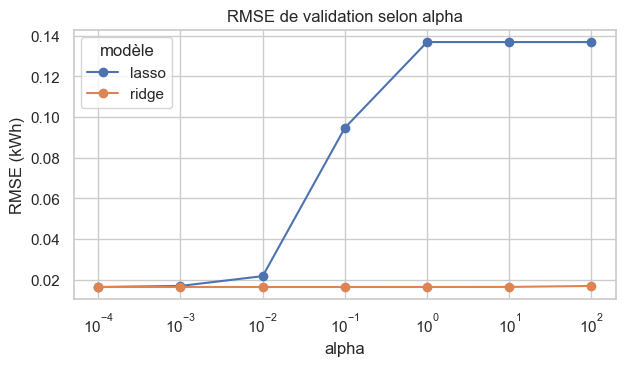

modèle       lasso
alpha       0.0001
MAE       0.012521
RMSE      0.016455
R2        0.977065
MAPE_%    3.557238
Name: 7, dtype: object

In [6]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
rows = []
for kind in ["ridge", "lasso"]:
    for a in alphas:
        m = ConsumptionModel(kind, a).fit(X_tr, y_tr)
        rows.append({"modèle": kind, "alpha": a, **m.evaluate(X_va, y_va)})
tuning = pd.DataFrame(rows)
tuning.pivot(index="alpha", columns="modèle", values="RMSE").plot(
    logx=True, marker="o", figsize=(7, 3.5), title="RMSE de validation selon alpha")
plt.ylabel("RMSE (kWh)"); plt.savefig(f"{FIG_DIR}/lr_alpha.png", dpi=150); plt.show()
best = tuning.sort_values("RMSE").iloc[0]
best

## 6. Modèle final : entraînement sur train + validation, évaluation sur test

In [7]:
X_trva, y_trva = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va])
final = ConsumptionModel(best["modèle"], float(best["alpha"])).fit(X_trva, y_trva)

comparison = pd.DataFrame({**baseline_metrics(X_te, y_te),
                           f"{best['modèle']} (alpha={best['alpha']})": final.evaluate(X_te, y_te)}).T
comparison

,MAE,RMSE,R2,MAPE_%
Persistance (t-1),0.047654,0.060426,0.851722,10.517780
Saisonnière (t-24),0.025862,0.041742,0.929242,5.440318
Saisonnière (t-168),0.024244,0.036229,0.946700,5.175687
lasso (alpha=0.0001),0.015817,0.021591,0.981069,3.432481


## 7. Validation croisée temporelle (stabilité du modèle)

In [8]:
cv = time_series_cv(X, y, kind=best["modèle"], alpha=float(best["alpha"]), n_splits=5)
display(cv.round(4))
print(cv[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).round(4))

,MAE,RMSE,R2,MAPE_%
fold,,,,
1,0.0145,0.0185,0.9648,4.1407
2,0.0178,0.0236,0.9803,3.9931
3,0.0170,0.0223,0.9782,3.8927
4,0.0122,0.0159,0.9755,3.5107
5,0.0156,0.0213,0.9815,3.4603


         MAE    RMSE      R2
mean  0.0154  0.0203  0.9761
std   0.0022  0.0031  0.0067


## 8. Prévisions vs réel

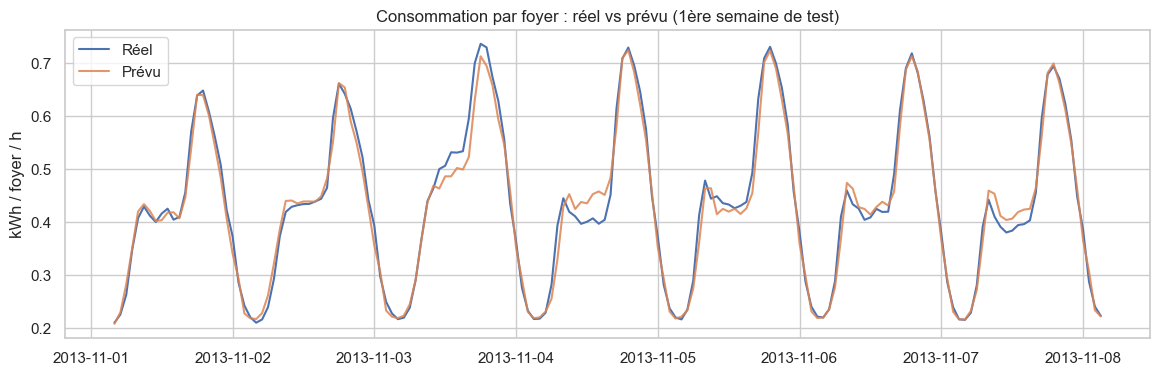

In [9]:
pred = pd.Series(final.predict(X_te), index=X_te.index)
N = 24 * 7
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_te.index[:N], y_te.values[:N], label="Réel")
ax.plot(pred.index[:N], pred.values[:N], label="Prévu", alpha=0.85)
ax.set_title("Consommation par foyer : réel vs prévu (1ère semaine de test)")
ax.set_ylabel("kWh / foyer / h"); ax.legend()
plt.savefig(f"{FIG_DIR}/lr_pred_vs_real.png", dpi=150); plt.show()

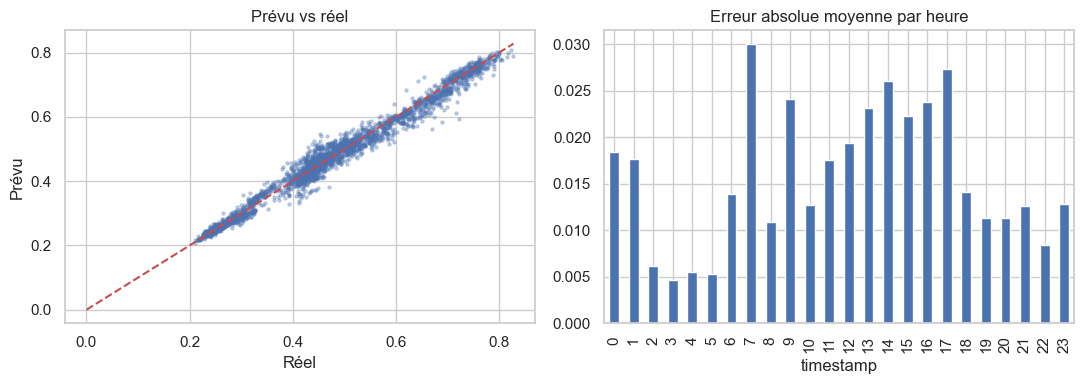

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_te, pred, s=5, alpha=0.3)
m = max(y_te.max(), pred.max()); ax[0].plot([0, m], [0, m], "r--")
ax[0].set_xlabel("Réel"); ax[0].set_ylabel("Prévu"); ax[0].set_title("Prévu vs réel")
err_by_hour = (y_te - pred).abs().groupby(y_te.index.hour).mean()
err_by_hour.plot(kind="bar", ax=ax[1], title="Erreur absolue moyenne par heure")
plt.tight_layout(); plt.show()

## 9. Analyse des résidus

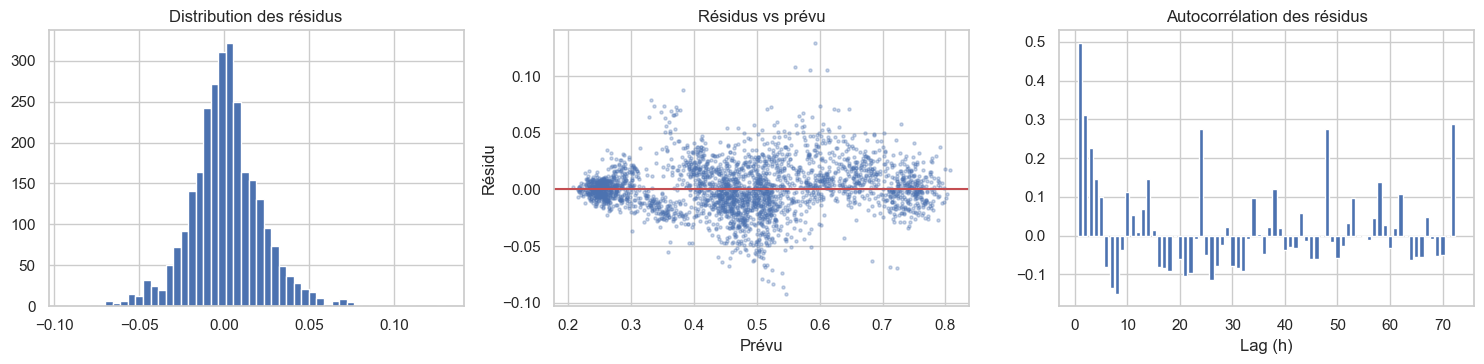

Biais moyen : 0.0008 kWh


In [11]:
resid = y_te - pred
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(resid, bins=50); ax[0].set_title("Distribution des résidus")
ax[1].scatter(pred, resid, s=5, alpha=0.3); ax[1].axhline(0, color="r")
ax[1].set_xlabel("Prévu"); ax[1].set_ylabel("Résidu"); ax[1].set_title("Résidus vs prévu")
lags = range(1, 73)
ax[2].bar(lags, [resid.autocorr(l) for l in lags]); ax[2].set_title("Autocorrélation des résidus")
ax[2].set_xlabel("Lag (h)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/lr_residuals.png", dpi=150); plt.show()
print("Biais moyen :", round(resid.mean(), 4), "kWh")

## 10. Coefficients (importance des variables)

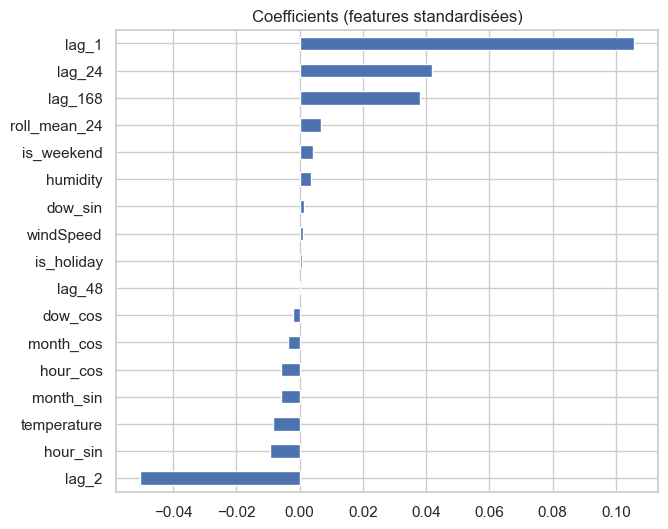

lag_1           0.1056
lag_2          -0.0503
lag_24          0.0417
lag_168         0.0379
hour_sin       -0.0094
temperature    -0.0085
roll_mean_24    0.0067
month_sin      -0.0060
hour_cos       -0.0057
is_weekend      0.0042
month_cos      -0.0036
humidity        0.0035
dow_cos        -0.0020
dow_sin         0.0013
windSpeed       0.0010
is_holiday      0.0007
lag_48          0.0000
dtype: float64

In [12]:
coefs = final.coefficients()
coefs.sort_values().plot(kind="barh", figsize=(7, 6), title="Coefficients (features standardisées)")
plt.savefig(f"{FIG_DIR}/lr_coefficients.png", dpi=150, bbox_inches="tight"); plt.show()
coefs.round(4)

## 11. Étude d'ablation : que valent les lags et la météo ?

In [13]:
configs = {"Calendrier seul": dict(use_weather=False, use_lags=False),
           "+ météo": dict(use_weather=True, use_lags=False),
           "+ lags": dict(use_weather=False, use_lags=True),
           "Tout": dict(use_weather=True, use_lags=True)}
rows = {}
for name, kw in configs.items():
    Xa, ya = build_features(df, **kw)
    (a_tr, b_tr), _, (a_te, b_te) = split_chronological(Xa, ya)
    rows[name] = ConsumptionModel("ridge", float(best["alpha"]) if best["modèle"] == "ridge" else 1.0
                                  ).fit(a_tr, b_tr).evaluate(a_te, b_te)
ablation = pd.DataFrame(rows).T
ablation[["MAE", "RMSE", "R2"]].round(4)

,MAE,RMSE,R2
Calendrier seul,0.0877,0.1016,0.5801
+ météo,0.0804,0.0932,0.6472
+ lags,0.0167,0.0225,0.9795
Tout,0.0158,0.0215,0.9813


## 12. Sauvegarde du modèle et des prévisions (pour la pipeline)

In [14]:
final.save("../models_saved", "linear_regression")
loaded = ConsumptionModel.load("../models_saved", "linear_regression")
print("Rechargé :", loaded.evaluate(X_te, y_te))

os.makedirs("../data/processed", exist_ok=True)
pd.DataFrame({"consumption_true": y_te, "consumption_pred": pred}).to_csv(
    "../data/processed/consumption_forecast_test.csv")

Rechargé : {'MAE': 0.01581691436802299, 'RMSE': 0.021591250969763012, 'R2': 0.9810688014042148, 'MAPE_%': 3.432480766737252}


## Conclusions
- Modèle retenu sur la validation : **Lasso, alpha = 0,0001** (presque identique à la régression linéaire simple).
- Sur le test (nov. 2013 → févr. 2014) : **MAE = 0,016 kWh, RMSE = 0,022 kWh, R² = 0,981, MAPE = 3,4 %**, contre R² = 0,947 et MAPE = 5,2 % pour la meilleure baseline (même heure la semaine précédente).
- Validation croisée temporelle (5 plis) : R² moyen 0,976 ± 0,007 → le modèle est stable dans le temps.
- Ablation : calendrier seul R² = 0,58 ; + météo 0,65 ; + lags 0,980 ; tout 0,981. Les **retards** expliquent presque toute la performance (surtout `lag_1`).
- Résidus centrés (biais ≈ 0,001 kWh) mais encore un peu autocorrélés : une partie de la dynamique n'est pas linéaire.
- Limite : avec `lag_1`, c'est une prévision **à 1 heure**. Pour la pipeline, la prévision par foyer est multipliée par 100 foyers.